<!-- DRAFT: Graeme to edit -->
# Day 2 · 03 (full data) — Lab: calendar, events and the hierarchy (25 min)

The original lab 03 adds price and promotion as future covariates and the hierarchy as
statics. Here price response gets its own notebook (04). We take the tuned N-BEATSx from
notebook 02 and ask whether it forecasts better when it also knows **when** a week is:

| Arm | Adds | Future covariates |
|---|---|---|
| `base` | nothing (the 02 model) | promo, discount depth, price index |
| `calendar` | week-of-year sine/cosine (2 pairs) and event weeks | + 4 Fourier + 4 events |
| `calendar_hierarchy` | the above plus the item's department as a static | as `calendar` |

The events are Easter (Good Friday), Anzac Day, Mother's Day and Christmas.

Goals

1. Build the three arms from configs, so any of them can be rebuilt with `gp.prepare(cfg)`.
2. Fit each with 3 seeds and **choose on the validation window**.
3. Refit the best feature arm, score the test window once, and compare it with `base`
   (notebook 02's tuned model).
4. Look at the event weeks themselves, which sit at the start of the test window.

See `docs/gfm_learnings.md` §7.

**In the chain:** reads `02_shortlist` and `00_baselines`, writes `03_features`.

In [1]:
import numpy as np
import pandas as pd

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: smooth seasons and sharp events

Fourier terms are like a dimmer switch turned slowly through the year. They can say "sales
rise towards December", but not "this one week is Easter", because Easter moves by up to five
weeks from year to year. An event dummy is a light switch: on in that one week, whenever it
falls. A department static is a name tag. It lets the model share patterns among items that
sit together on the shelf, without one model per department.

<!-- DRAFT: Graeme to edit -->
## 1. The starting point and the three arms

The model settings, step budget and covariates come from `02_shortlist`. Each arm is a small
config, and `gp.prepare(cfg)` turns it into training data. Switches that are off are written
out too, so the config says exactly what was used.

In [2]:
shortlist_cfg = gd.load_config("02_shortlist")
examples = gd.load_config("00_baselines")["examples"]
params = shortlist_cfg["best_params"]
max_steps = shortlist_cfg["max_steps"]
noise_floor = shortlist_cfg["noise_floor"]
base_exog = shortlist_cfg["futr_exog"]
y_shift = shortlist_cfg["y_shift"]

panel = gd.train_panel()
train, test = bc.split(panel, cutoff=bc.TEST_START)
info = gplt.series_table(panel)

NO_FEATURES = {"deflate": False, "events": False, "fourier_k": 0, "hierarchy_level": None}
CALENDAR = {**NO_FEATURES, "events": True, "fourier_k": 2}
CALENDAR_HIERARCHY = {**CALENDAR, "hierarchy_level": "department_id"}
calendar_exog = base_exog + gp.fourier_cols(2) + gp.EVENT_COLS

arm_cfgs = {
    "base": {"features": NO_FEATURES, "futr_exog": base_exog, "y_shift": y_shift},
    "calendar": {"features": CALENDAR, "futr_exog": calendar_exog, "y_shift": y_shift},
    "calendar_hierarchy": {"features": CALENDAR_HIERARCHY, "futr_exog": calendar_exog,
                           "y_shift": y_shift},
}
ALIASES = {"base": "NBEATSx_base", "calendar": "NBEATSx_calendar",
           "calendar_hierarchy": "NBEATSx_cal_hier"}

arm_rows = []
for arm, cfg in arm_cfgs.items():
    arm_rows.append({"arm": arm, **cfg["features"], "future covariates": len(cfg["futr_exog"])})
pd.DataFrame(arm_rows).set_index("arm")

,deflate,events,fourier_k,hierarchy_level,future covariates
arm,,,,,
base,False,False,0,None,3
calendar,False,True,2,None,11
calendar_hierarchy,False,True,2,department_id,11


<!-- DRAFT: Graeme to edit -->
### Where the events fall

The data has fewer than two years of training weeks, so the model sees **one** Easter, one
Anzac Day and one Mother's Day to learn from. The validation window (January to early April
2025) holds **no** event at all. It can judge the Fourier terms and the department static,
but not the event dummies.

The test window is different. Good Friday 2025 (18 April) falls in the **first test week**,
the week starting 16 April, and Anzac Day in the second. Easter also fell in the research's
held-back window, one reason its price response did not transfer (§6, [100k set]). How to
represent Easter is still an open question (§9). The table below lists every event week.

In [3]:
def window_of(ds: pd.Series) -> pd.Series:
    """Which window each week belongs to: inner train, validation, test or later."""
    ds = pd.to_datetime(ds)
    test_end = pd.Timestamp(bc.TEST_START) + pd.Timedelta(weeks=bc.H)
    conditions = [ds < pd.Timestamp(bc.VALID_START), ds < pd.Timestamp(bc.TEST_START),
                  ds < test_end]
    return pd.Series(np.select(conditions, ["inner train", "validation", "test"], "after test"),
                     index=ds.index)


event_panel = gp.add_events(panel)
event_weeks = (event_panel.select(["ds"] + gp.EVENT_COLS).unique("ds").sort("ds")
               .to_pandas().melt(id_vars="ds", var_name="event", value_name="on"))
event_weeks = event_weeks[event_weeks["on"] > 0].drop(columns="on").sort_values("ds")
event_weeks["window"] = window_of(event_weeks["ds"])
event_weeks.reset_index(drop=True)

,ds,event,window
0,2023-12-20,ev_christmas,inner train
1,2024-03-27,ev_easter,inner train
2,2024-04-24,ev_anzac,inner train
3,2024-05-08,ev_mothers_day,inner train
4,2024-12-25,ev_christmas,inner train
5,2025-04-16,ev_easter,test
6,2025-04-23,ev_anzac,test
7,2025-05-07,ev_mothers_day,test


<!-- DRAFT: Graeme to edit -->
### Hierarchy ids are labels, not numbers

`department_id` is a number in the data, but department 41 is not "more" than department 3.
Fed in as a number, the network would read a distance between them that means nothing, and
the scaler would treat it as a quantity (§7, [method]). So `gp.hierarchy_statics` one-hot
encodes the 12 largest departments; the rest share an "other" column.

In [4]:
hierarchy = gp.hierarchy_statics(panel, "department_id")
print(f"{panel['department_id'].n_unique()} departments → {hierarchy.shape[1] - 1} one-hot "
      f"columns")
hierarchy.head()

149 departments → 13 one-hot columns


,unique_id,department_-1,department_3,department_4,department_12,department_15,department_16,department_21,department_27,department_33,department_39,department_70,department_73,department_121
0,10000_S1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,10001_S1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,10002_S1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,10003_S1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10004_S1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


<!-- DRAFT: Graeme to edit -->
## 2. Fit the three arms on the tuning split

`gp.prepare(cfg, cutoff=bc.VALID_START)` builds each arm on the inner training weeks and
forecasts the validation window. The reference price and statics use the inner weeks only.
Calendar columns are known for any week, and a department is a membership, so neither needs
a statistic from later weeks.

In [5]:
def fit_arm(arm: str, data: gd.NixtlaData, stage: str) -> list[dict]:
    """The 02 model on one arm's data, 3 seeds; ``stage`` is ``valid`` or ``test``."""
    def build(seed):
        return gd.build_nbeatsx(params, data, max_steps, seed, ALIASES[arm])

    return gd.fit_seeds(build, data, f"03_{stage}_{arm}")


valid_runs = {}
for arm, cfg in arm_cfgs.items():
    _, inner, valid, data = gp.prepare(cfg, panel=panel, cutoff=bc.VALID_START)
    print(f"{arm}: {len(data.futr_exog)} future covariates, {len(data.stat_exog)} statics")
    valid_runs[arm] = fit_arm(arm, data, "valid")

base: 3 future covariates, 3 statics


2026-11-23 22:00:48,837	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-23 22:00:49,204	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


calendar: 11 future covariates, 3 statics


calendar_hierarchy: 11 future covariates, 16 statics


<!-- DRAFT: Graeme to edit -->
## 3. Choose on the validation window

Each seed is scored on its own (median RMSSE over the evaluation series). The rule is fixed
before looking: start from `base`, and move to a richer arm only if it beats the current
choice by more than the **noise floor** from notebook 02.

In [6]:
valid_scores = {}
rows = []
for arm, arm_runs in valid_runs.items():
    scores = gd.seed_medians(arm_runs, valid, inner)
    health = gd.summaries(arm_runs)
    valid_scores[arm] = scores
    rows.append({"arm": arm, "median_rmsse_valid": scores.mean(), "seed_sd": scores.std(),
                 "oscillation": health["oscillation"].median(),
                 "best_frac": health["best_frac"].median(),
                 "minutes_per_fit": health["fit_seconds"].mean() / 60})
valid_table = pd.DataFrame(rows).set_index("arm")

valid_median = valid_table["median_rmsse_valid"]
chosen = "base"
for arm in list(arm_cfgs)[1:]:                  # simplest first
    if valid_median[chosen] - valid_median[arm] > noise_floor:
        chosen = arm
feature_arms = valid_table.drop(index="base")
challenger = chosen if chosen != "base" else feature_arms["median_rmsse_valid"].idxmin()
print(f"noise floor {noise_floor:.4f} | chosen: {chosen} | refitted for test: {challenger}")
valid_table.round(4)

noise floor 0.0048 | chosen: base | refitted for test: calendar_hierarchy


,median_rmsse_valid,seed_sd,oscillation,best_frac,minutes_per_fit
arm,,,,,
base,0.6131,0.0048,0.0059,0.9469,8.6778
calendar,0.7174,0.0104,0.0058,0.4236,8.7372
calendar_hierarchy,0.7032,0.0065,0.0079,0.5233,8.4222


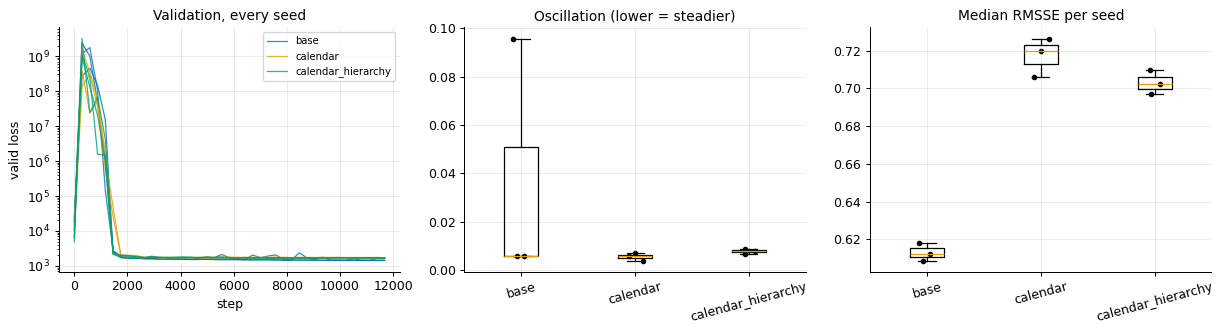

In [7]:
gplt.plot_arm_comparison(valid_runs, metrics=valid_scores)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* If no arm clears the noise floor, the choice stays `base`. The extra columns cost nothing to
  compute, but a feature that cannot be shown to help is one more thing to explain.
* Validation median RMSSE: base ≈ 0.613, calendar ≈ 0.717, calendar + hierarchy ≈ 0.703.
* Remember what validation could not test: it has no event week. A calendar arm that ties
  here may still differ in the Easter and Anzac weeks of the test window.

*Reference run: full panel, GPU box, 3 seeds. Exact numbers vary with seed and hardware; the
reading should not.*

<!-- DRAFT: Graeme to edit -->
## 4. Refit on the full training window and score the test window once

The best feature arm (the chosen one, or the runner-up if `base` was kept) is refitted with
three seeds, and its seed-mean forecast goes on the board. `base` is not refitted: it is
notebook 02's `NBEATSx_tuned` (same settings, same data), so we reuse its saved forecasts.

In [8]:
base_col = ALIASES["base"]
challenger_col = ALIASES[challenger]
_, _, _, full_data = gp.prepare(arm_cfgs[challenger], panel=panel)
test_runs = fit_arm(challenger, full_data, "test")
challenger_fcst = gd.seed_forecasts(test_runs)[["unique_id", "ds", f"{challenger_col}_mean"]]
challenger_fcst = challenger_fcst.rename(columns={f"{challenger_col}_mean": challenger_col})

gd.save_forecasts(challenger_fcst, "03_features")
gd.record(challenger_fcst, test, train,
          lab=f"03 calendar and hierarchy ({len(gd.SEEDS)}-seed mean)",
          fit_seconds={challenger_col: gd.summaries(test_runs)["fit_seconds"].mean()},
          notes=f"chosen on validation: {chosen}; fit_seconds is per seed")

base_fcst = pd.read_parquet(gd.FORECAST_DIR / "02_tuned.parquet")
base_fcst = base_fcst[["unique_id", "ds", "NBEATSx_tuned"]].rename(
    columns={"NBEATSx_tuned": base_col})
test_fcst = base_fcst.merge(challenger_fcst, on=["unique_id", "ds"])
gd.median_board()

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
1,NBEATSx_recipe_mean,0.568,1.114,0.286,1999,01 recipe (3-seed mean),506.900
2,NBEATSx_tuned,0.568,1.114,0.286,1999,02 HPO round 1 (3-seed mean),537.767
3,LightGBM,0.569,1.161,0.295,1999,00 baselines (full panel),NaN
4,NBEATSx_cal_hier,0.647,1.170,0.328,1999,03 calendar and hierarchy (3-seed mean),527.233
5,AutoETS,0.708,1.285,0.426,1999,00 baselines (full panel),NaN
6,Naive,0.771,1.332,0.470,1999,00 baselines (full panel),NaN
7,NBEATSx_off_mean,0.773,741.411,8.717,1999,01 recipe (3-seed mean),509.233
8,SeasonalNaive,0.929,1.525,0.438,1999,00 baselines (full panel),NaN


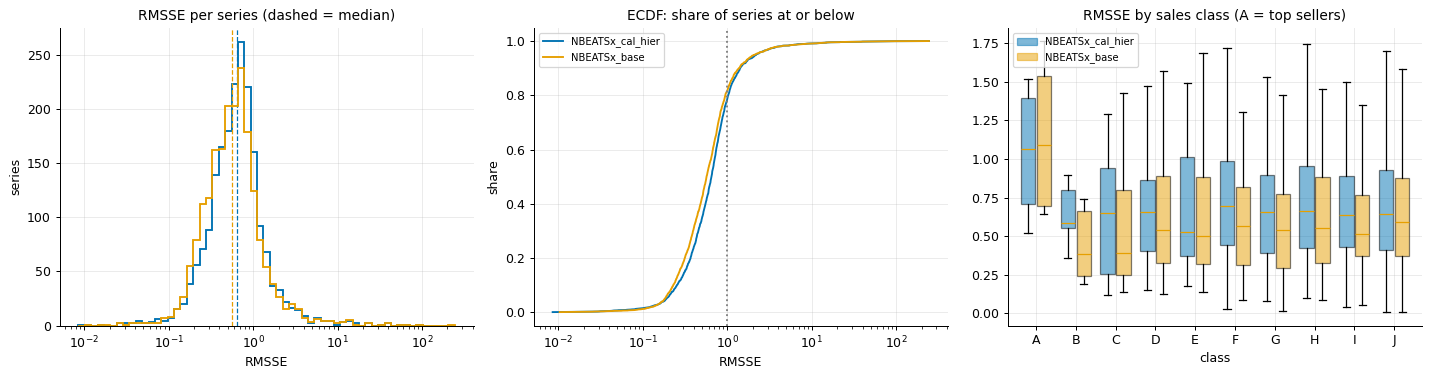

In [9]:
rmsse = gd.per_series(gd.score(test_fcst, test, train))
gplt.plot_error_dist(rmsse, info, models=[challenger_col, base_col])

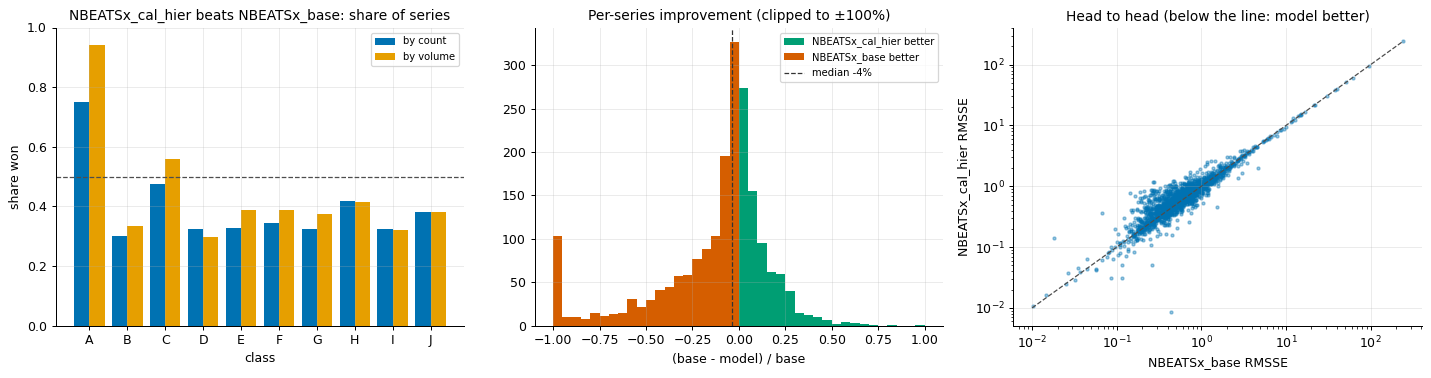

,win_share,win_share_volume,n
sale_class,,,
A,0.750,0.942,4.0
B,0.300,0.334,10.0
C,0.474,0.560,19.0
D,0.323,0.296,31.0
E,0.326,0.388,46.0
F,0.343,0.388,67.0
G,0.323,0.374,96.0
H,0.419,0.413,148.0
I,0.324,0.321,259.0


In [10]:
gplt.plot_wins(rmsse, info, model=challenger_col, baseline=base_col)

<!-- DRAFT: Graeme to edit -->
## 5. The event weeks

RMSSE pools the 14 test weeks, so it hides single weeks. To see Easter and Anzac Day, go week
by week: total forecast over the evaluation series ÷ total sold − 1 (the bias), with each
event marked. Positive means over-forecast.

In [11]:
def weekly_bias(fcst: pd.DataFrame, actual, models: list[str]) -> pd.DataFrame:
    """Per test week: total forecast ÷ total actual − 1 over the eval ids (forecasts ≥ 0)."""
    act = gd.only(actual, gd.eval_ids()).select("unique_id", "ds", "y").to_pandas()
    act["ds"] = pd.to_datetime(act["ds"])
    d = act.merge(fcst, on=["unique_id", "ds"])
    d[models] = d[models].clip(lower=0)
    totals = d.groupby("ds")[["y"] + models].sum()
    out = pd.DataFrame({m: totals[m] / totals["y"] - 1 for m in models})
    out.insert(0, "units sold", totals["y"])
    return out


week_events = event_weeks.assign(ds=pd.to_datetime(event_weeks["ds"])).set_index("ds")["event"]
bias = weekly_bias(test_fcst, test, [base_col, challenger_col])
bias.insert(0, "event", week_events.reindex(bias.index).fillna(""))
bias.round(3)

,event,units sold,NBEATSx_base,NBEATSx_cal_hier
ds,,,,
2025-04-16,ev_easter,8823077.72,-0.036,-0.024
2025-04-23,ev_anzac,8068197.53,0.061,-0.008
2025-04-30,,6954349.90,0.217,0.180
2025-05-07,ev_mothers_day,7963709.82,0.056,-0.036
2025-05-14,,9282081.44,-0.004,-0.112
2025-05-21,,7534019.27,0.049,0.023
2025-05-28,,8300859.60,0.032,-0.033
2025-06-04,,7682697.50,0.054,-0.015
2025-06-11,,8489198.67,0.053,-0.045


<!-- DRAFT: Graeme to edit -->
### Reading the result

* Look at the first two rows. A model without events cannot know that the week of 16 April is
  Easter. Its bias there is what the event dummy has to fix.
* Easter-week bias: base ≈ −3.6%, feature arm ≈ −2.4%.
* One good Easter week does not make a feature. The dummy was learnt from a single Easter, and
  a seed-mean forecast can still be lucky. Compare with the other weeks' bias first.

*Exact numbers vary with seed and hardware; the reading should not.*

<!-- DRAFT: Graeme to edit -->
The example series from notebook 00, with both forecasts and the event weeks marked (dotted).

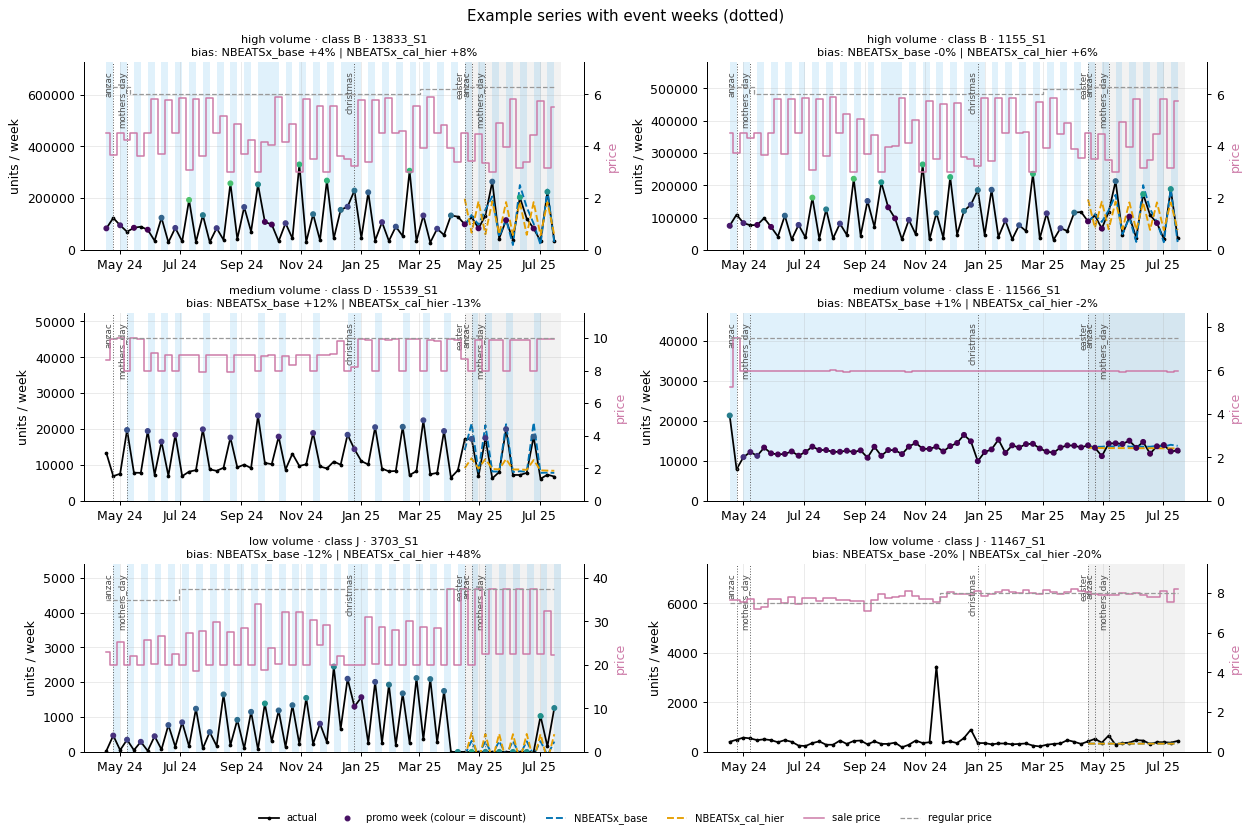

In [12]:
gplt.plot_series_price(event_panel, examples, test_fcst, models=[base_col, challenger_col],
                       events=True, title="Example series with event weeks (dotted)")

In [13]:
gd.save_config("03_features", {
    "params": params,
    "features": arm_cfgs[chosen]["features"],
    "futr_exog": arm_cfgs[chosen]["futr_exog"],
    "y_shift": y_shift,
    "max_steps": max_steps,
    "seeds": gd.SEEDS,
    "median_rmsse": {"valid": valid_table["median_rmsse_valid"].round(4).to_dict(),
                     "test": rmsse.median().round(4).to_dict()},
    "arm": chosen,
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/03_features.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* The validation window had no event week; the test window starts with two. Did the choice
  made on validation hold up on test? What would a fairer tuning window look like when the
  events you care about come once a year?
* One Easter in training is one example. Can a network learn "Easter" from a single week, or
  is the dummy mostly noise until there are more years of data?
* A model that misses Easter may also misread a promotion that falls in it, and credit the
  holiday's lift to the price. Why does that matter for notebook 04?

**Try it:** set `"fourier_k": 4` in `CALENDAR` (and use `gp.fourier_cols(4)`) to give the
calendar sharper seasonal shapes, and see whether the validation score moves past the noise
floor.